# 02 · Modelling, threshold and explanations

Training lives in `src/fraud/train.py` (run `uv run python -m fraud.train`), so the API and this notebook use exactly the same code. This notebook reads its outputs (`reports/metrics.json`, `models/model.joblib`) and tells the story.

**Question:** which model should a fraud team put in front of TRANSFER and CASH_OUT transactions, at what threshold, and can it explain itself?

In [1]:
import json, pandas as pd, joblib
from IPython.display import Image, display
m = json.load(open("../reports/metrics.json"))
pd.DataFrame(m["validation"]).T.round(4)

,pr_auc,roc_auc,recall_at_p90,recall_at_p95
logreg_classweight,0.9959,0.9987,0.9968,0.9968
logreg_smote,0.9910,0.9979,0.9959,0.9959
lgbm_unweighted,0.9964,0.9986,0.9959,0.9959
lgbm_classweight,0.8942,0.9966,0.9943,0.9943
lgbm_smote,0.9968,0.9987,0.9959,0.9959
lgbm_ablation_no_drain,0.8465,0.9921,0.6818,0.5755
logreg_ablation_no_drain,0.3050,0.9673,0.0000,0.0000


## 1. Model comparison (validation set, 415k rows, ~0.30% fraud)
**Finding:** unweighted LightGBM, SMOTE LightGBM and both logistic regressions all score PR-AUC ≥ 0.99, and logistic regression is within 0.001 of LightGBM. SMOTE adds nothing measurable. Class weights *hurt* LightGBM (0.89): the heavy weight (~340×) pushes some legit transactions to very high scores, which costs precision.

**Why it matters:** PaySim fraud is close to linearly separable once you know whether the account was drained. We serve the **unweighted LightGBM**: its gap to the best variant (SMOTE) is noise, and it keeps probabilities on the true base rate, which matters because the API returns a probability. A tree model also gives exact, fast SHAP values.

Accuracy is not shown on purpose: predicting "legit" for everything scores 99.7%.

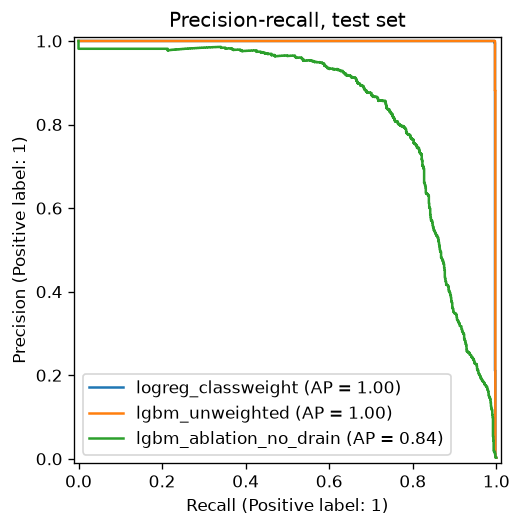

,served LightGBM,logreg baseline,LightGBM ablation (no drain features),logreg ablation (no drain features)
pr_auc,0.9975,0.9969,0.8370,0.2944
roc_auc,0.9981,0.9983,0.9955,0.9694
recall_at_p90,0.9968,0.9968,0.6688,0.0000
recall_at_p95,0.9968,0.9968,0.5706,0.0000


In [2]:
display(Image("../reports/figures/pr_curve.png"))
pd.DataFrame({"served LightGBM": m["test"], "logreg baseline": m["test_logreg_baseline"],
              "LightGBM ablation (no drain features)": m["test_ablation_no_drain"],
              "logreg ablation (no drain features)": m["test_logreg_ablation_no_drain"]}).round(4)

## 2. The honest check: ablation
Removing `drains_account` and `amount_to_balance` drops LightGBM's PR-AUC from **0.997 to 0.837** and recall at 95% precision from **99.7% to 57%**. Logistic regression collapses to **0.29**, which is where the tree model earns its place.

**Why it matters:** most of the "near-perfect" score comes from one simulator behaviour (PaySim's fraud agent always empties the account). Real fraud is messier, so read the ablation number as the more realistic one.

## 3. Threshold tuning with a cost matrix
Assumptions (PaySim units treated as RM):
- **missed fraud** costs the transaction amount
- **every alert** costs RM15 (analyst review and customer friction)

The threshold is the cheapest one on the validation set. If several are within 0.1% of that cost, we pick the one that catches the most fraud.

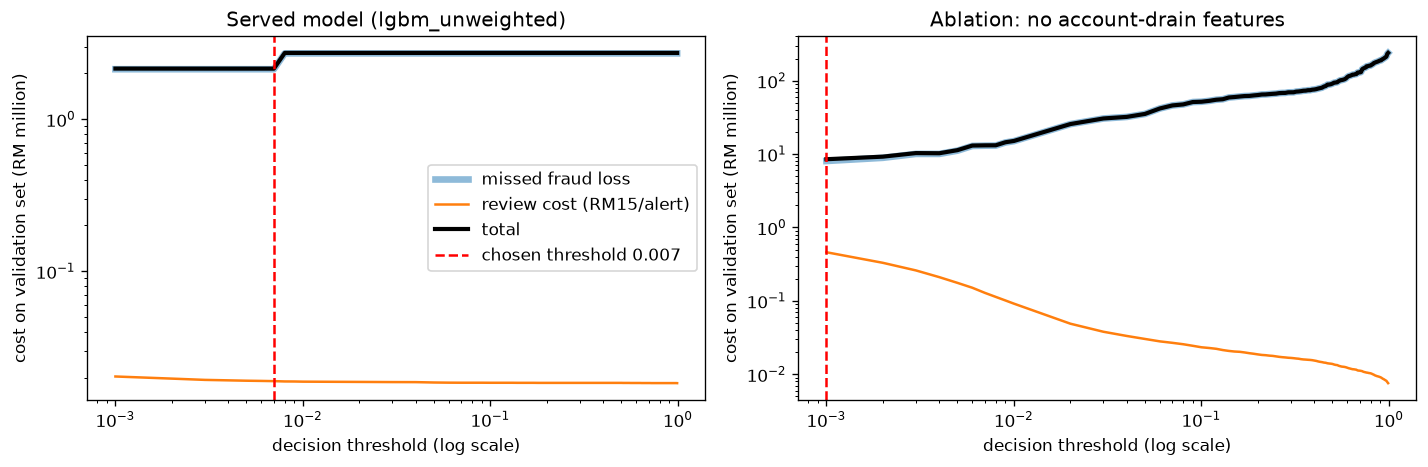

,total_cost,missed_fraud_loss,review_cost,alerts,tp,fp,fn
no model (all fraud lost),"1,885,200,330",nan,nan,nan,nan,nan,nan
served @ 0.007,"840,948","822,153","18,795","1,253","1,228",25,4
served @ 0.5,"840,573","822,153","18,420","1,228","1,228",0,4
ablation @ 0.001,"5,349,700","4,888,270","461,430","30,762","1,224","29,538",8
ablation @ 0.5,"75,056,308","75,041,623","14,685",979,858,121,374


In [3]:
display(Image("../reports/figures/cost_curve.png"))
rows = {"no model (all fraud lost)": {"total_cost": m["test_cost_no_model"]},
        f"served @ {m['threshold']}": m["test_cost_at_threshold"],
        "served @ 0.5": m["test_cost_at_0.5"],
        f"ablation @ {m['ablation_threshold']}": m["ablation_test_cost_at_threshold"],
        "ablation @ 0.5": m["ablation_test_cost_at_0.5"]}
pd.DataFrame(rows).T[["total_cost","missed_fraud_loss","review_cost","alerts","tp","fp","fn"]].style.format("{:,.0f}")

**Finding:** for the served model the threshold barely matters. Cost is flat from 0.008 to 0.99, and the low threshold catches one more large fraud. For the realistic ablation model, the threshold *is* the business decision: moving from the default 0.5 to the cost-optimal threshold cuts test-set cost from about RM75M to about RM5M. The price is roughly 30k alerts (7% of traffic).

**Why it matters:** missed fraud is so expensive compared with a review that the cost model says to review almost everything risky. In practice analyst capacity caps the alert volume, so the next version should optimise under a daily alert budget.

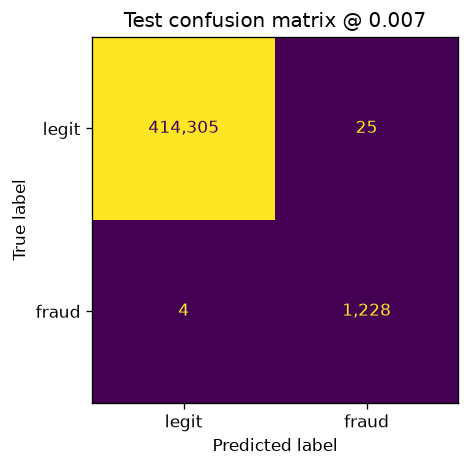

In [4]:
display(Image("../reports/figures/confusion_matrix.png"))

## 4. Explanations (SHAP)
**Global:** balances and the account-drain flag dominate. Hour and amount matter less.

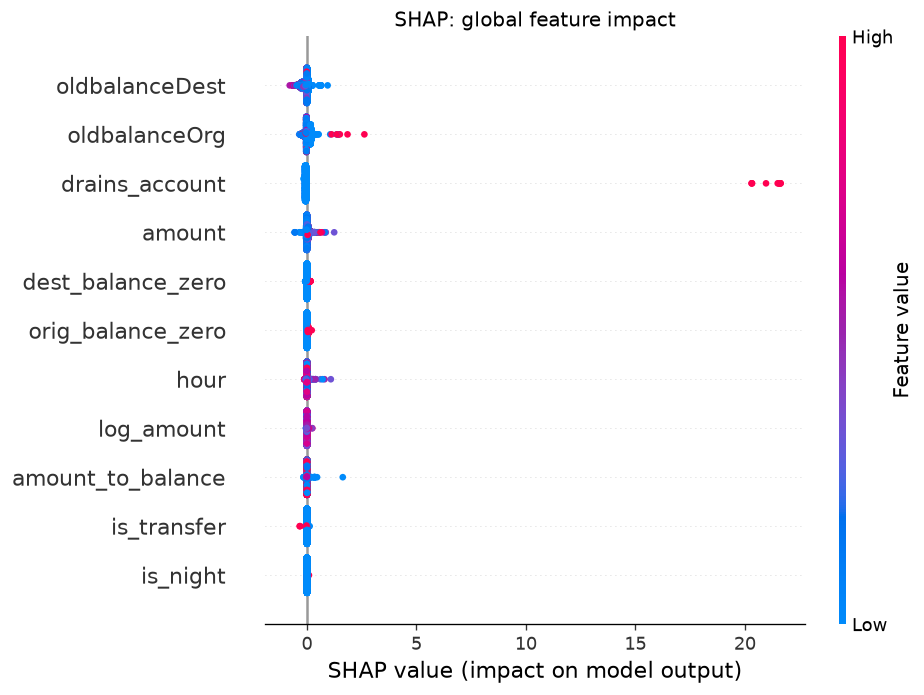

,mean |SHAP|
oldbalanceDest,0.1249
oldbalanceOrg,0.1164
drains_account,0.1078
amount,0.0435
dest_balance_zero,0.0212
orig_balance_zero,0.0205
hour,0.0130
log_amount,0.0068
amount_to_balance,0.0057
is_transfer,0.0043


In [5]:
display(Image("../reports/figures/shap_summary.png"))
pd.Series(m["shap_mean_abs"], name="mean |SHAP|").to_frame()

**Per transaction:** the API returns the top 3 SHAP contributions in plain English. Two examples:

In [6]:
import sys; sys.path.insert(0, "../src")
from fraud.explain import Explainer
bundle = joblib.load("../models/model.joblib")
exp = Explainer(bundle["model"])
txns = [
  {"step": 3, "type": "TRANSFER", "amount": 250000.0, "oldbalanceOrg": 250000.0, "oldbalanceDest": 0.0},
  {"step": 14, "type": "CASH_OUT", "amount": 1800.0, "oldbalanceOrg": 52000.0, "oldbalanceDest": 120000.0},
]
from fraud.features import build_features
probs = bundle["model"].predict_proba(build_features(pd.DataFrame(txns)))[:, 1]
for t, p, r in zip(txns, probs, exp.reasons(txns)):
    print(f"{t['type']} {t['amount']:,.0f}  ->  p(fraud)={p:.4f}")
    for x in r: print("   -", x["text"])

TRANSFER 250,000  ->  p(fraud)=1.0000
   - transaction empties the sender's account (raises risk)
   - receiver balance before the transaction is 0.00 (raises risk)
   - sender balance before the transaction is 250,000.00 (raises risk)
CASH_OUT 1,800  ->  p(fraud)=0.0000
   - sender keeps part of their balance (lowers risk)
   - amount is 3% of the sender's balance (raises risk)
   - sender balance before the transaction is 52,000.00 (lowers risk)


C:\Users\zeeq1\Downloads\Downloads\For New Lappy\uni stuff 2\Part 6\Career\Portfolio Project\02-machine-learning\05-fraud-detection-api\.venv\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


## Takeaways
- Served model: LightGBM, test PR-AUC 0.997 and recall 99.7% at 95% precision, but most of that comes from the PaySim simulator's account-draining pattern.
- Without that feature, PR-AUC is 0.84. That is the number to quote when asked how it would do on real data.
- Cost-based thresholding matters most when the model is imperfect. Here it saves about RM70M on the ablation model's test set compared with the default 0.5.
- A time-based split (train steps ≤ 500, test later) gives PR-AUC 0.9998, so the result is not an artifact of the random split.